In [ ]:
!pip install pulser

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.0/271.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.6/122.6 kB 7.6 MB/s eta 0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0


/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  sim = pulser_simulation.QutipBackend(seq)
/tmp/ipykernel_2460/898973936.py:32: DeprecationWarning: 'QutipBackend

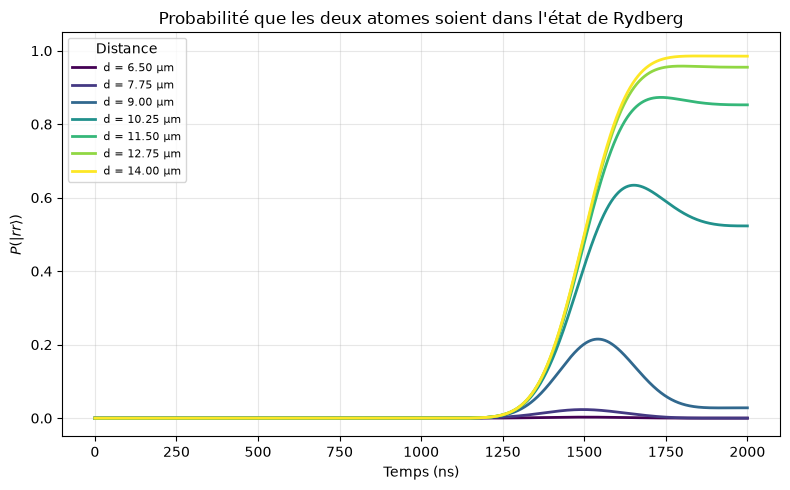

In [ ]:
from pulser import Pulse, Register, Sequence
from pulser.devices import Device, MockDevice
import numpy as np
from pulser.devices import DigitalAnalogDevice
from pulser import Pulse, BlackmanWaveform
import pulser_simulation
import matplotlib.pyplot as plt
import matplotlib.cm as cm


distances = np.linspace(6.5, 14, 7)
pi_wf = BlackmanWaveform(duration=1000, area=np.pi)
pulse = Pulse.ConstantDetuning(phase=0, detuning=0, amplitude=pi_wf)

l= []

for d in distances:
  reg = Register({"a0": (0, 0), "a1": (d, 0)})
  seq = Sequence(reg, DigitalAnalogDevice)
  seq.available_channels
  seq.declare_channel("ch0", "rydberg_local")
  seq.target("a1", "ch0")

  seq.add(pulse, "ch0")

  seq.target("a0", "ch0")
  seq.add(pulse, "ch0")

  seq.get_measurement_basis
  seq.measure(basis="ground-rydberg")

  sim = pulser_simulation.QutipBackend(seq)

  res = sim.run()

  final = res.states

  p_rr_t = []
  for state in final:
      vec = np.abs(state.full().flatten())**2
      p_rr_t.append(vec[0])

  l.append(p_rr_t)


l = np.array(l)
times = np.linspace(0, seq.get_duration(), l.shape[1])

fig, ax = plt.subplots(figsize=(8, 5))
colors = cm.viridis(np.linspace(0, 1, len(distances)))

for i, d in enumerate(distances):
    ax.plot(times, l[i], color=colors[i], label=f"d = {d:.2f} µm", linewidth=2)

ax.set_xlabel("Temps (ns)")
ax.set_ylabel(r"$P(|rr\rangle)$")
ax.set_title("Probabilité que les deux atomes soient dans l'état de Rydberg")
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)
ax.legend(title="Distance", loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()



# Interpretation des résultas


Pas eu le temps...
Mais la théorie est confirmé